# Plot all Agenticoptimizer convergence runs
Plots Random, Monte Carlo, GA, and all completed agentic runs. Repeated/seeded families show individual curves, a bold mean, and a shaded ±1 standard-deviation band. Invalid or interrupted folders are skipped.

In [1]:
from pathlib import Path
import json, re, warnings, zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
try:
    from IPython.display import display
except ImportError:
    display=lambda x: None
RESULTS_ROOT=Path('/home/mahpe/Code/Agentic_optimizer/Runs/runs/independent_global_optimizations')
REFERENCE_ROOT=Path('/home/mahpe/Code/Agentic_optimizer/Runs/runs/enumeration_optimized')
OUTPUT_DIR=Path.cwd()/'notebook_convergence_plots'
MAX_EVALUATIONS=200
SHOW_REFERENCE=True
SHOW_INDIVIDUALS=True
SHADE_STD=True
MATERIAL='Cu3Au_123'
SYSTEMS=['AlReGe','Ba2ScTaO6','CoPt','Cu3Au','Cu3Au_123','FeCo','FeCo_331','FePt','InCuTe2','LiYS2','Ni2SbTe2','ThMn2Co3','TiCuNi','V2ZnO4','NaFeGaPO4_nNa16']
SKIP=('aborted','interrupted','invalid','excluded','over200')
BASE_COLORS={'random':'c','mc':'orange','ga':'m'}
BASE_LABELS={'random':'Random','mc':'MCMC','ga':'GA'}
OUTPUT_DIR.mkdir(exist_ok=True)


In [2]:
def cum(y): 
    return np.minimum.accumulate(np.asarray(y,float))

def curve(path,method=None):
    d=json.loads(Path(path).read_text())
    rows=d['steps']
    if method=='ga' or ('best_energy_eV' in rows[0] and 'energy' not in rows[0]):
        pop=int(d.get('population_size',1))
        y=np.repeat(cum([r['best_energy_eV'] for r in rows]),pop)   
        x=np.arange(1,len(y)+1)
    else:
        key='energy' if 'energy' in rows[0] else 'best_energy_eV'
        x=np.array([int(r.get('step',i)) for i,r in enumerate(rows)]); y=cum([r[key] for r in rows])
    keep=x<=MAX_EVALUATIONS; return x[keep],y[keep]

def hold(x,y,grid):
    z=np.full(len(grid),np.nan); ok=(grid>=x[0])&(grid<=x[-1])
    idx=np.searchsorted(x,grid[ok],side='right')-1
    z[ok]=y[np.clip(idx,0,len(y)-1)]
    return z

def reference(system):
    p=REFERENCE_ROOT/system/'optimized_all.extxyz'
    if not SHOW_REFERENCE or not p.exists(): 
        return None
    from ase.io import read
    aa=read(p,index=':')
    return min(float(a.info['energy']) if 'energy' in a.info else float(a.get_potential_energy()) for a in aa)

def family(name): 
    return re.sub(r'_seed\d+$','',name)

def valid_agentic(system):
    out=[]
    for p in sorted((RESULTS_ROOT/system).glob('*/summary.json')):
        n=p.parent.name
        if re.fullmatch(r'(random|mc|ga)_seed\d+',n) or any(t in n.lower() for t in SKIP): 
            continue
        out.append((n,p))
    return out

def groups(system):
    g={}
    for m in ('random','mc','ga'):
        for seed in range(5):
            p=RESULTS_ROOT/system/f'{m}_seed{seed}'/'summary.json'
            if p.exists(): 
                g.setdefault(m,[]).append(curve(p,m))
    for n,p in valid_agentic(system):
        try: 
            g.setdefault(family(n),[]).append(curve(p))
        except Exception as e: 
            warnings.warn(f'Skipping {p}: {e}')
    return g

def label(n):
    for old,new in [('agentic_without_unique_database_','agentic: '),('agentic_with_unque_database','agentic: DB-assisted'),('elite_v2_max200_cluster_',''),('all15_model_comparison','matched'),('all15_frozen','all15 frozen'),('adaptive_stop','adaptive'),('50_steps','50 steps')]: 
        n=n.replace(old,new)
    return n[:70]

def draw_group(ax,curves,color,name,grid):
    if SHOW_INDIVIDUALS:
        for x,y in curves: ax.plot(x,y,color=color,alpha=.18,lw=.8)
    stack=np.vstack([hold(x,y,grid) for x,y in curves])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        mean=np.nanmean(stack,0)
        std=np.nanstd(stack,0)
    ok=np.isfinite(mean)
    if SHADE_STD and len(curves)>1: 
        ax.fill_between(grid[ok],(mean-std)[ok],(mean+std)[ok],color=color,alpha=.18,lw=0)
    ax.plot(grid[ok],mean[ok],color=color,lw=2.4,label=f'{name}' if len(curves)>1 else name)


In [3]:
BASE_COLORS

{'random': 'c', 'mc': 'orange', 'ga': 'm'}

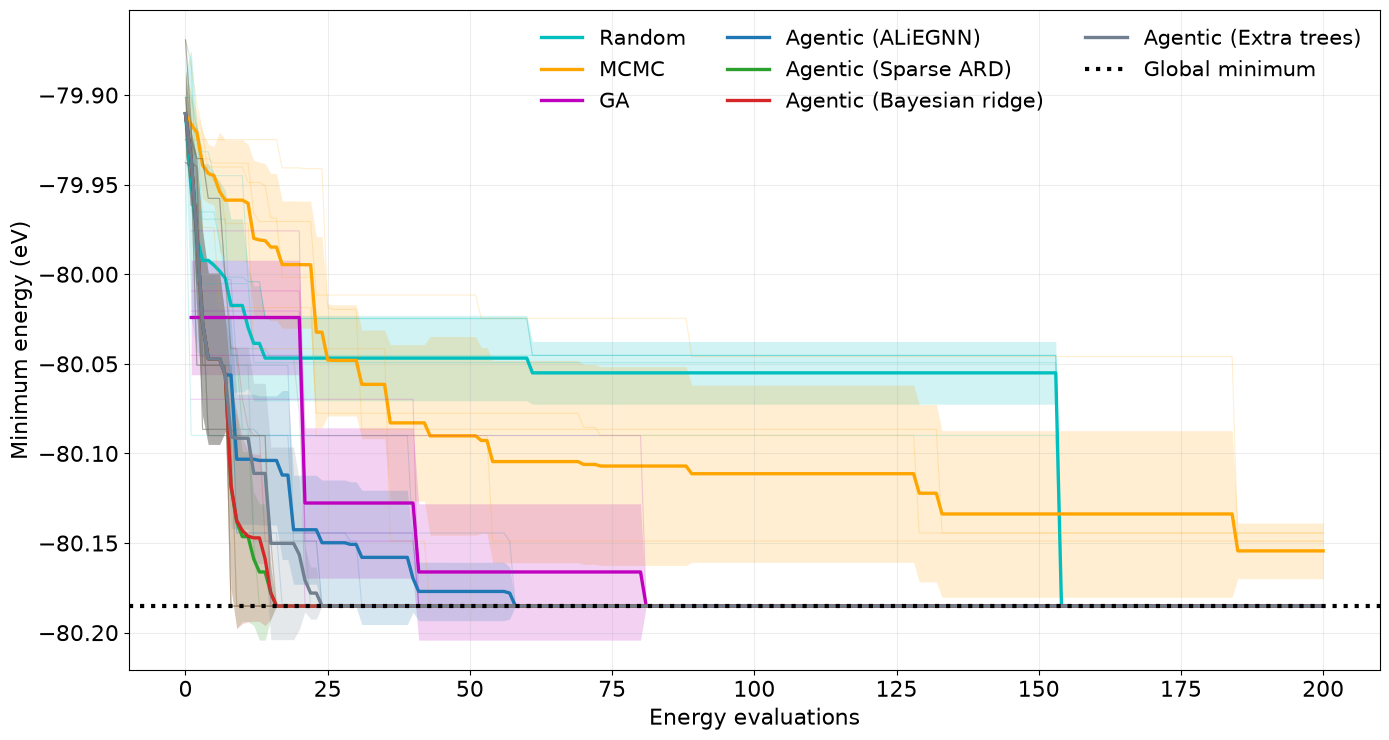

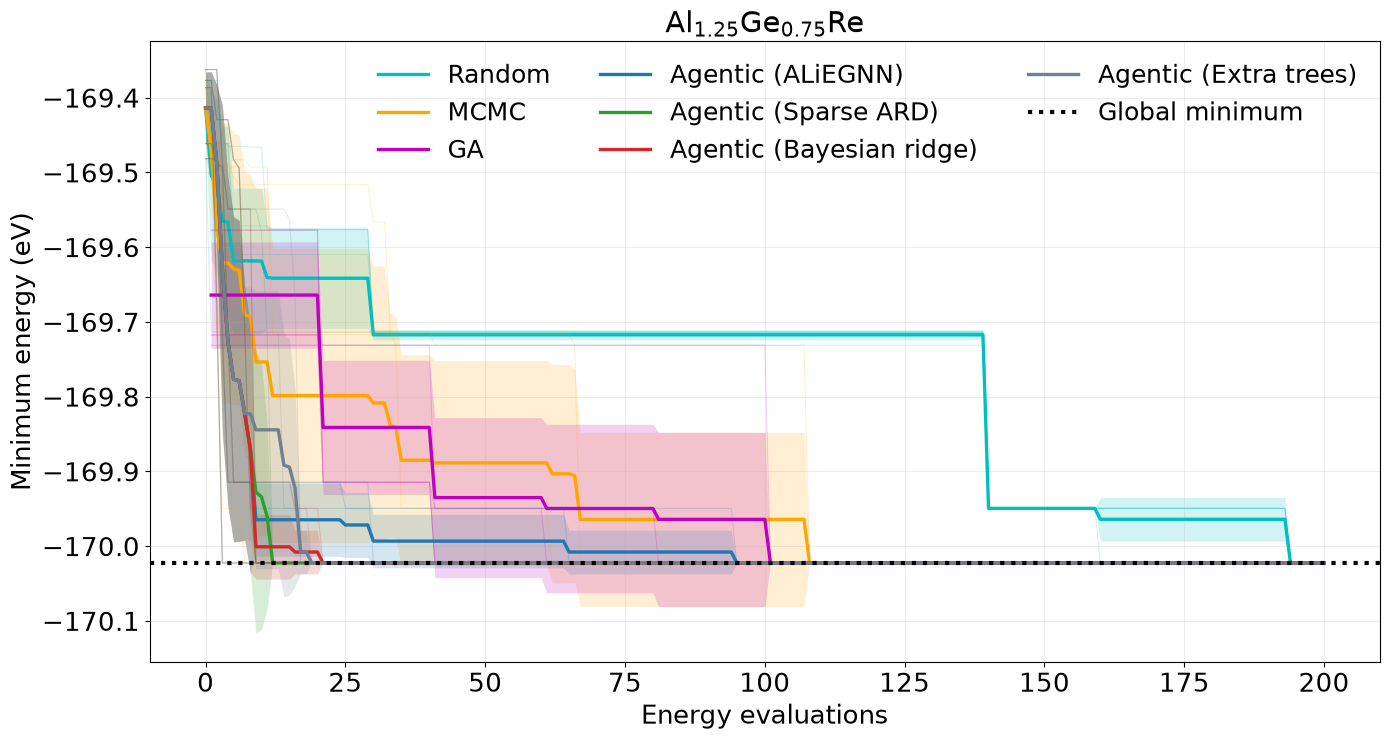

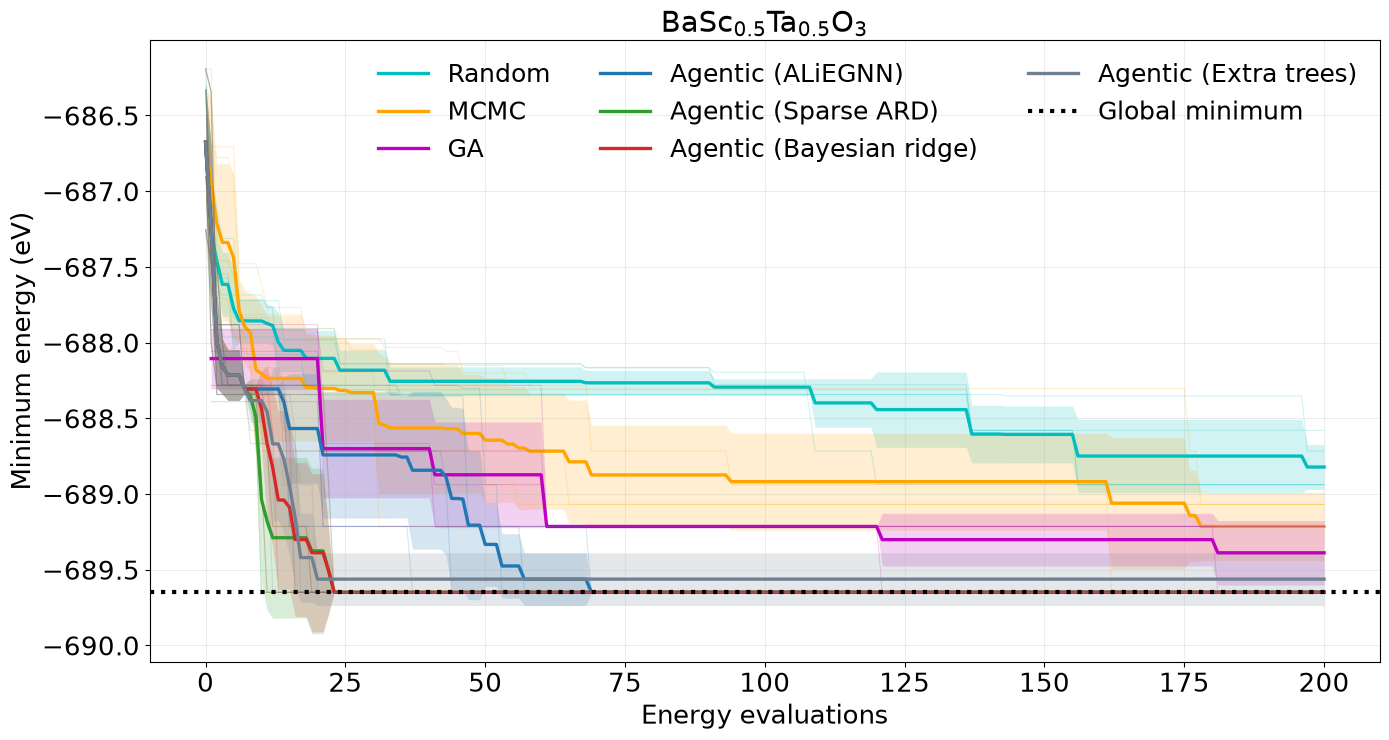

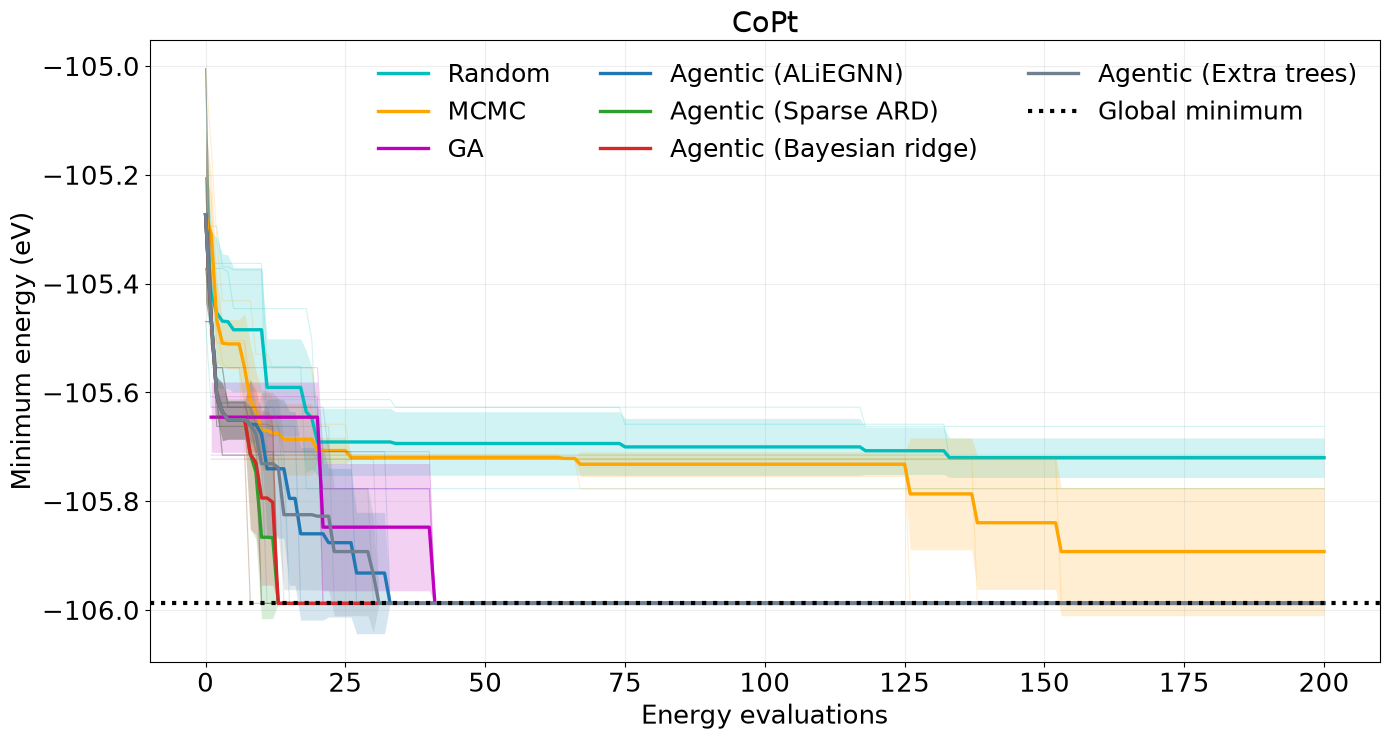

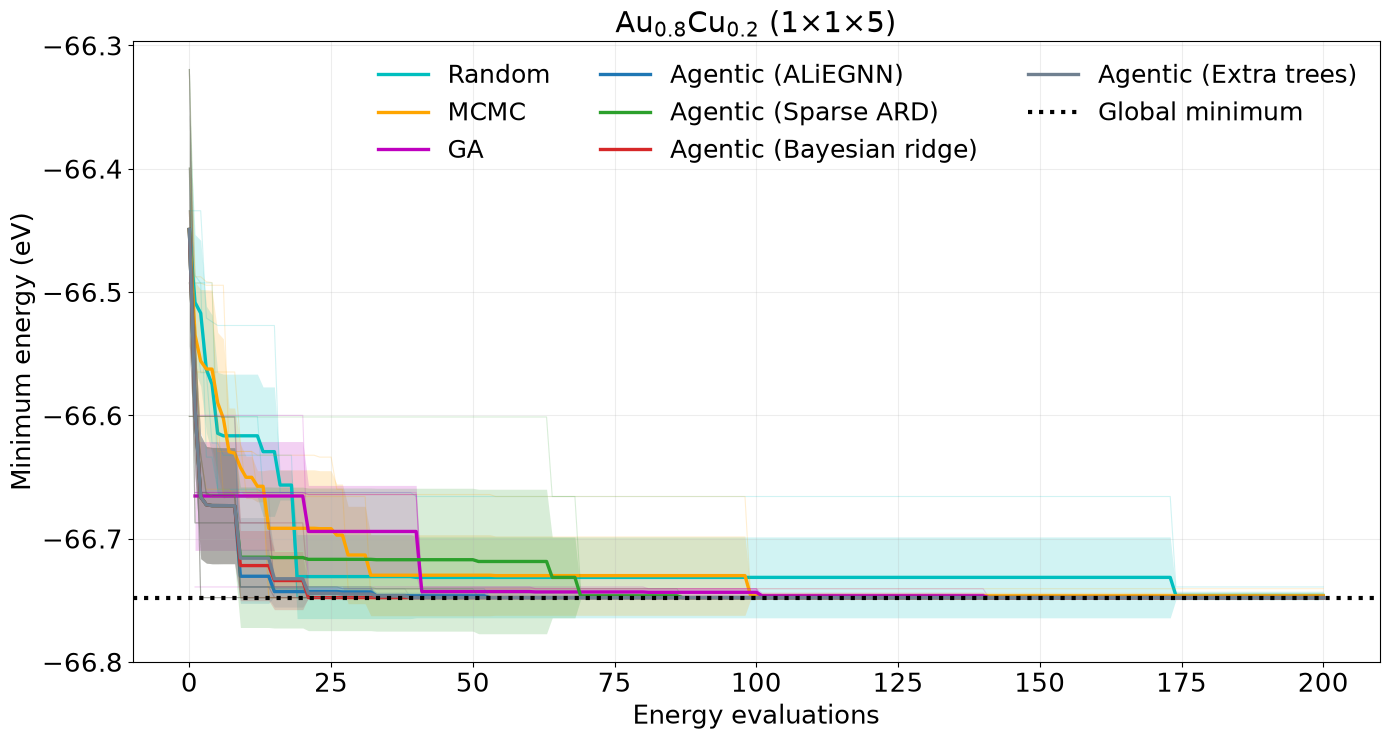

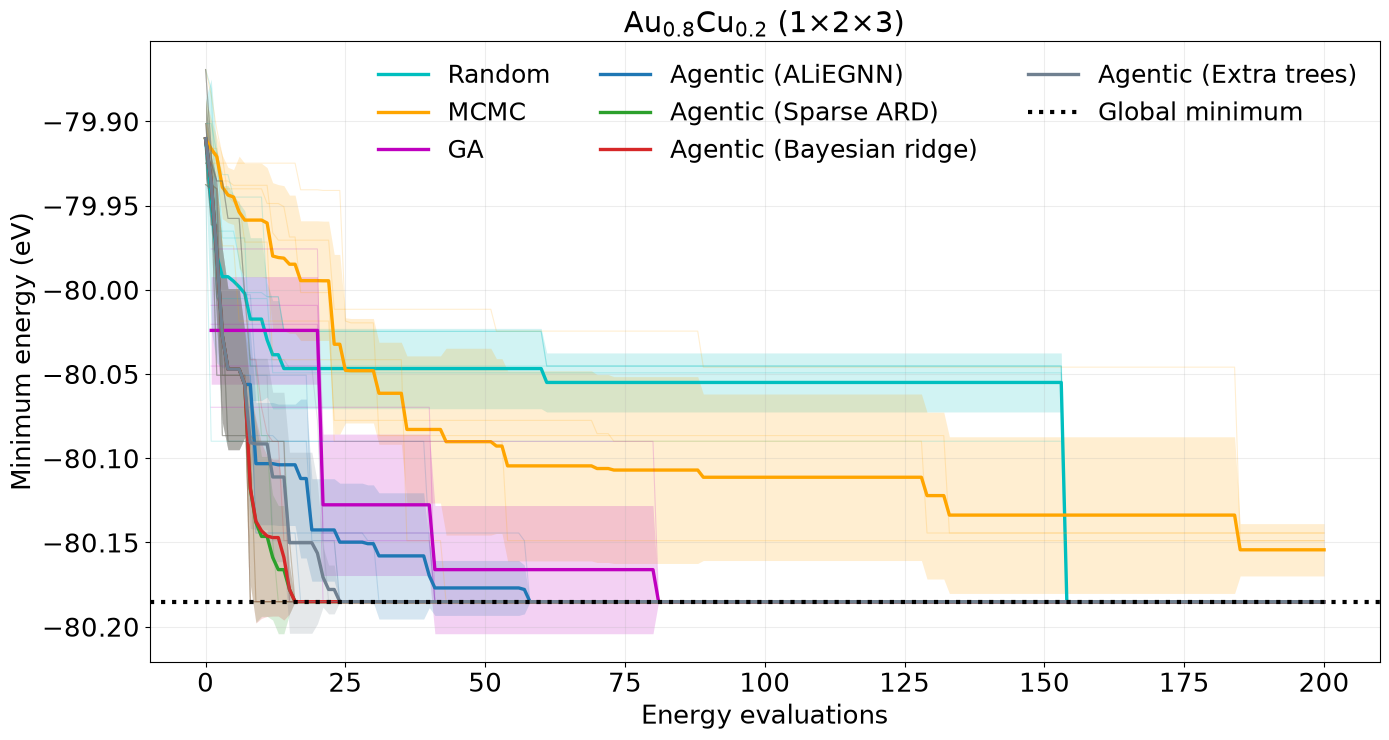

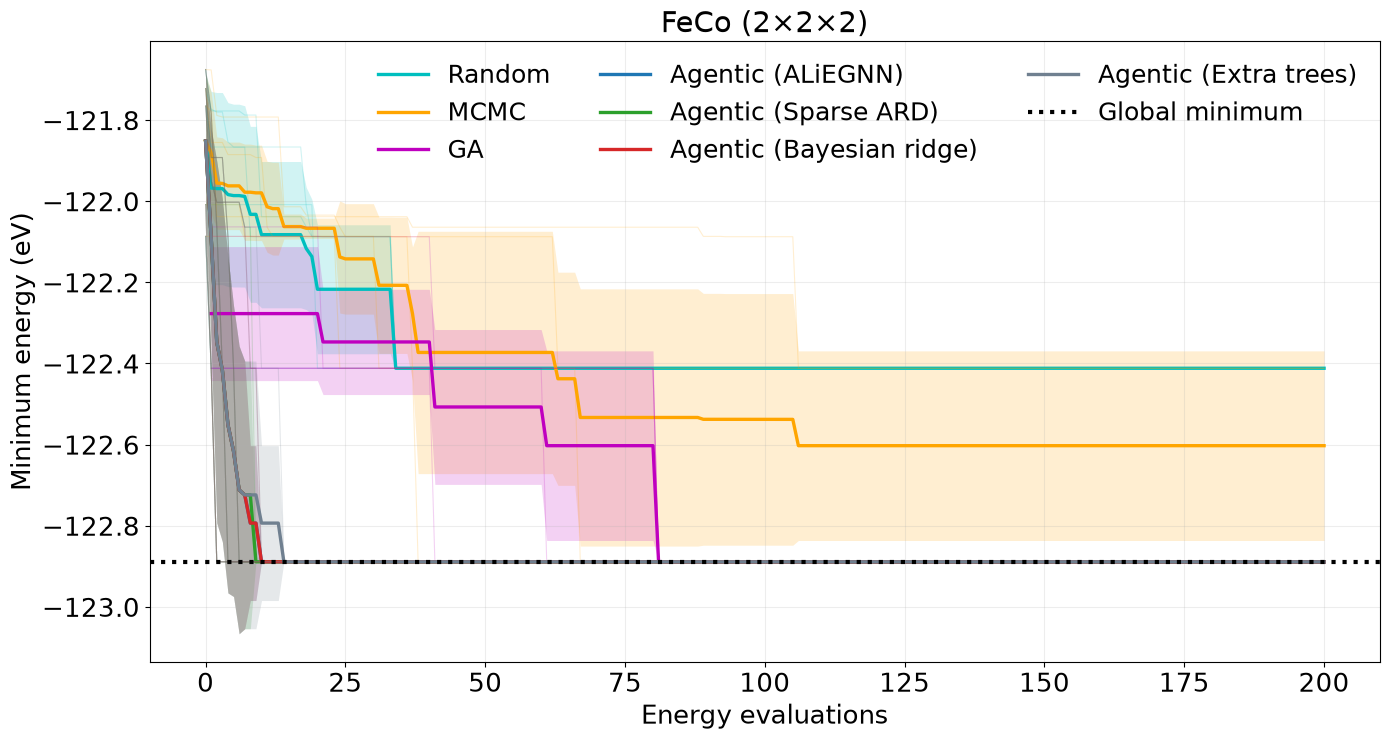

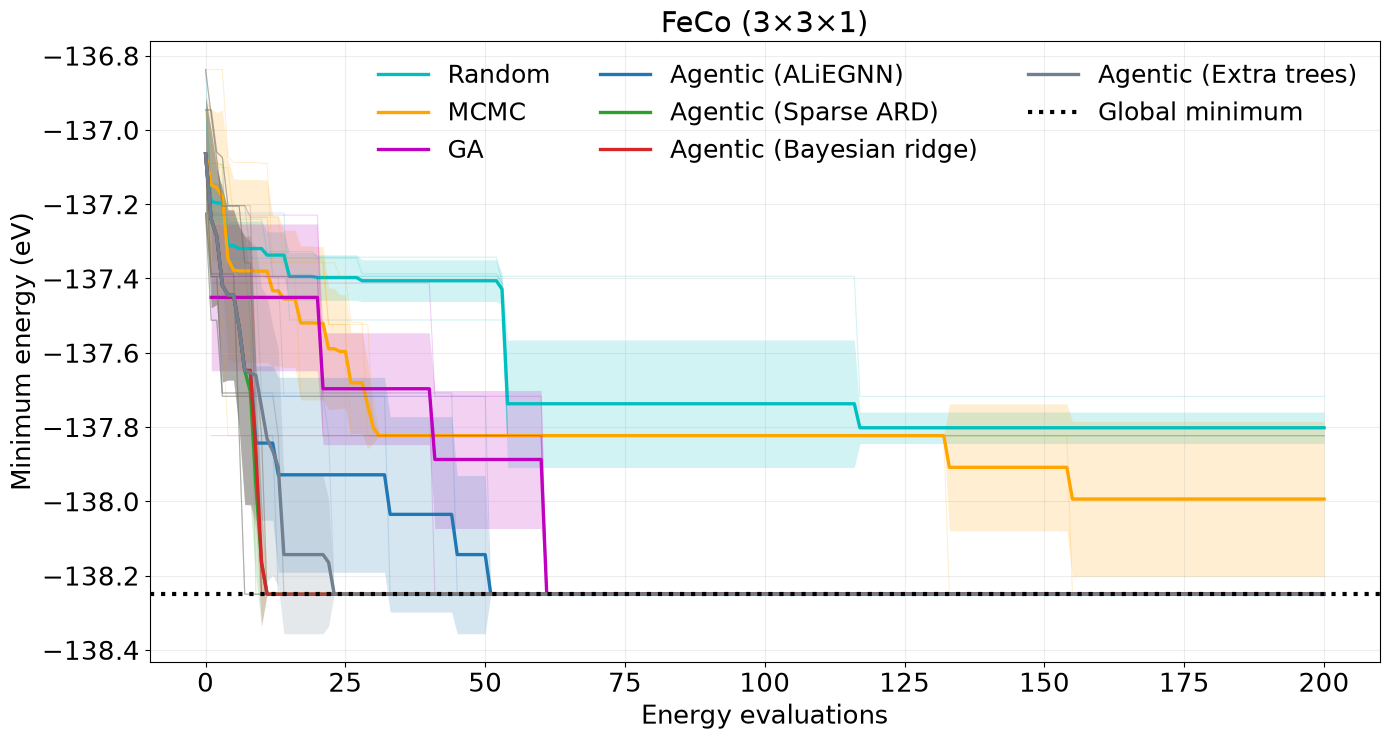

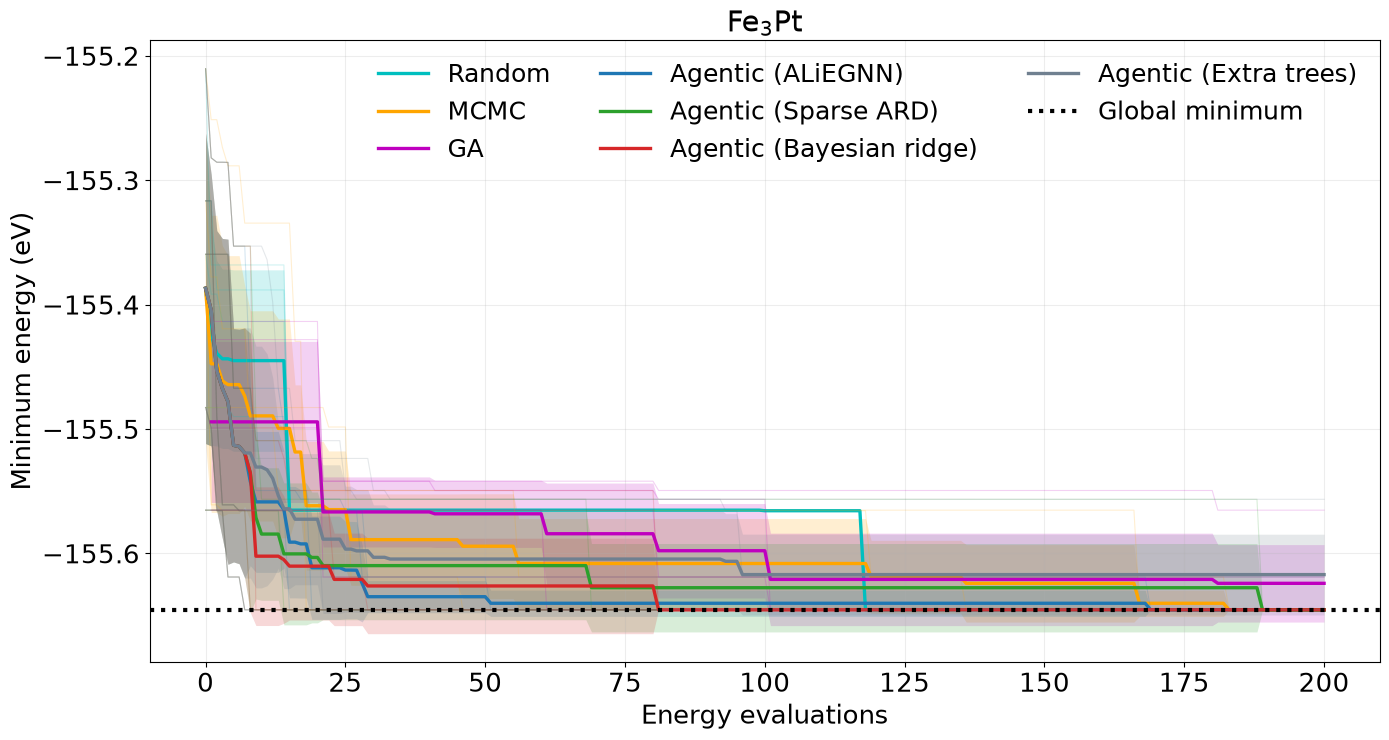

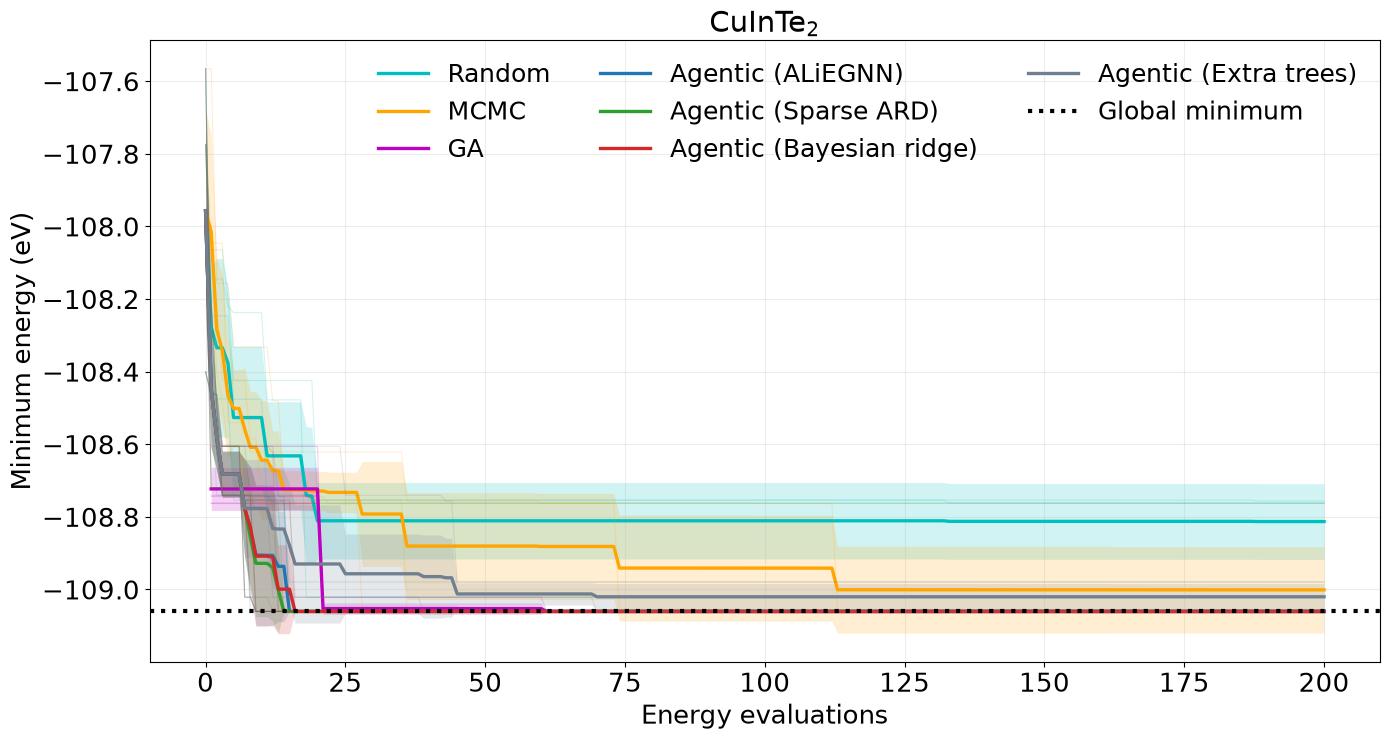

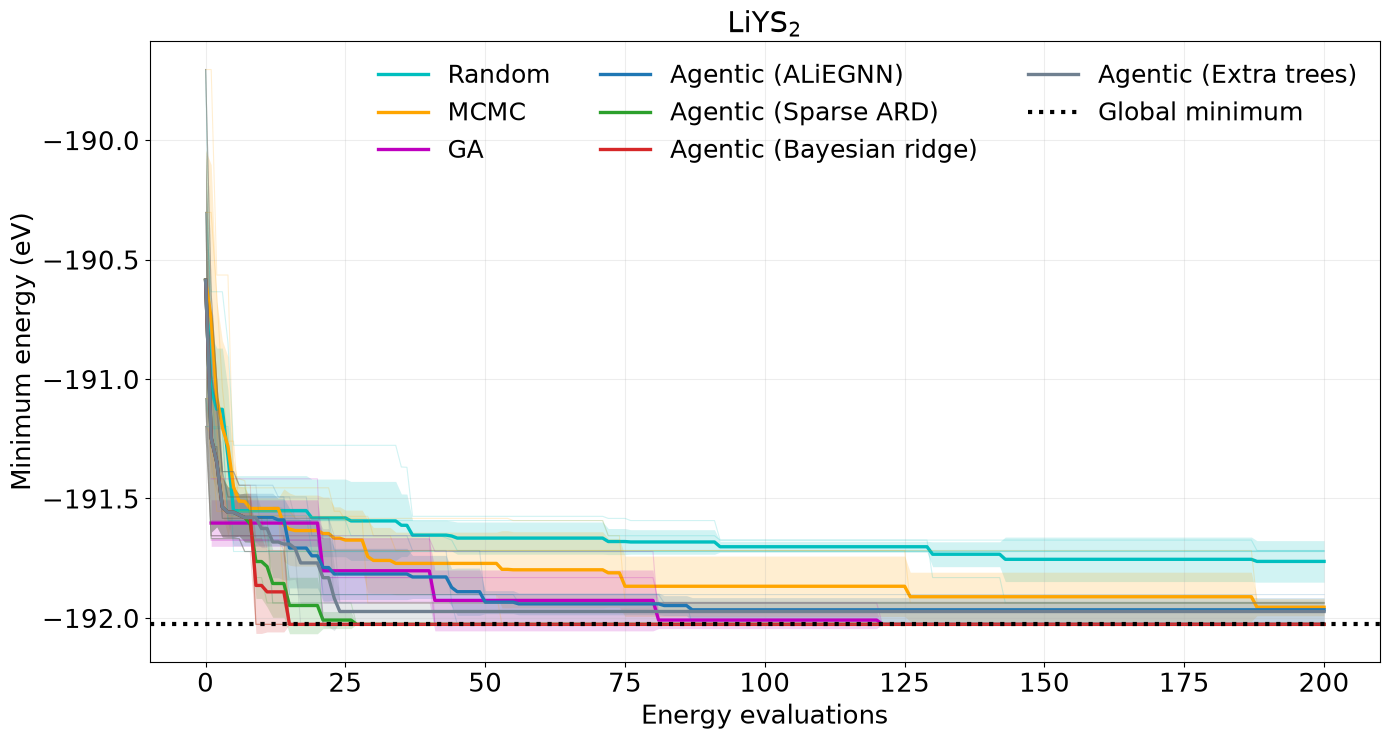

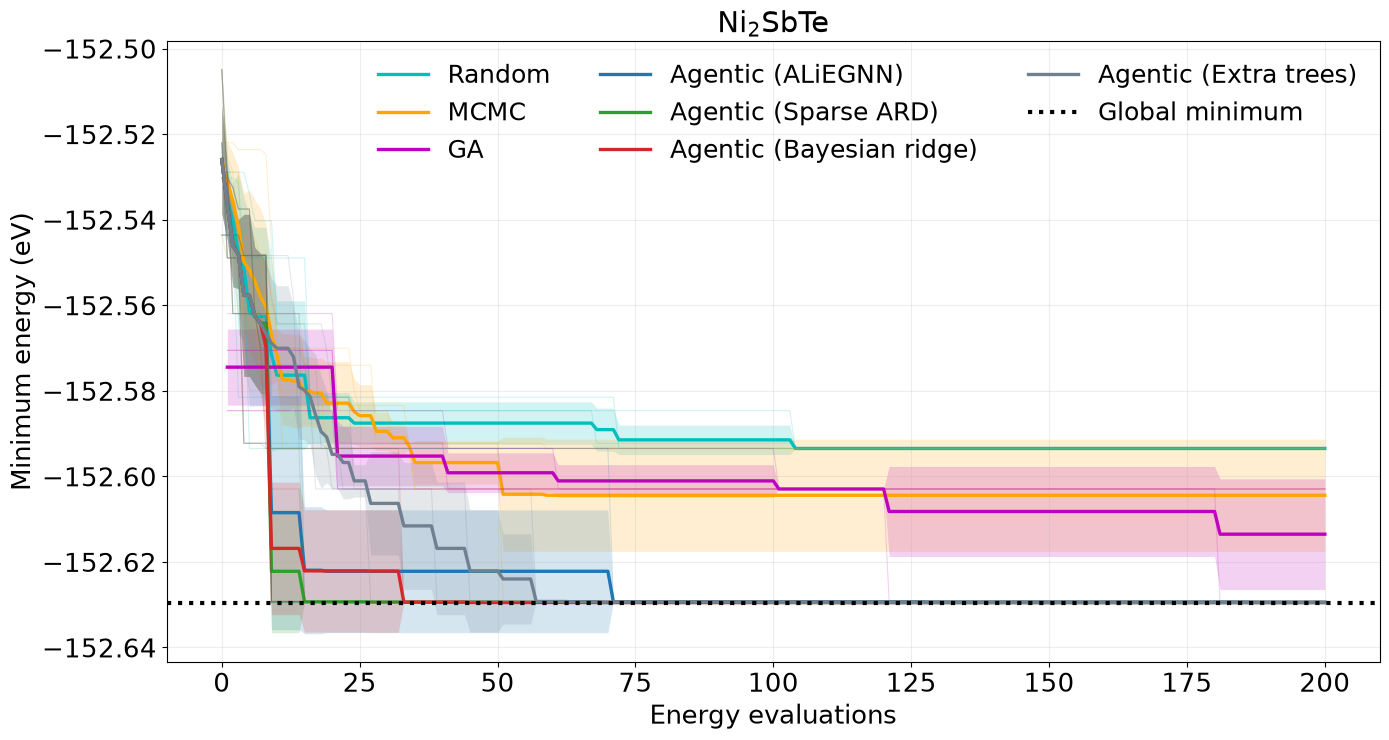

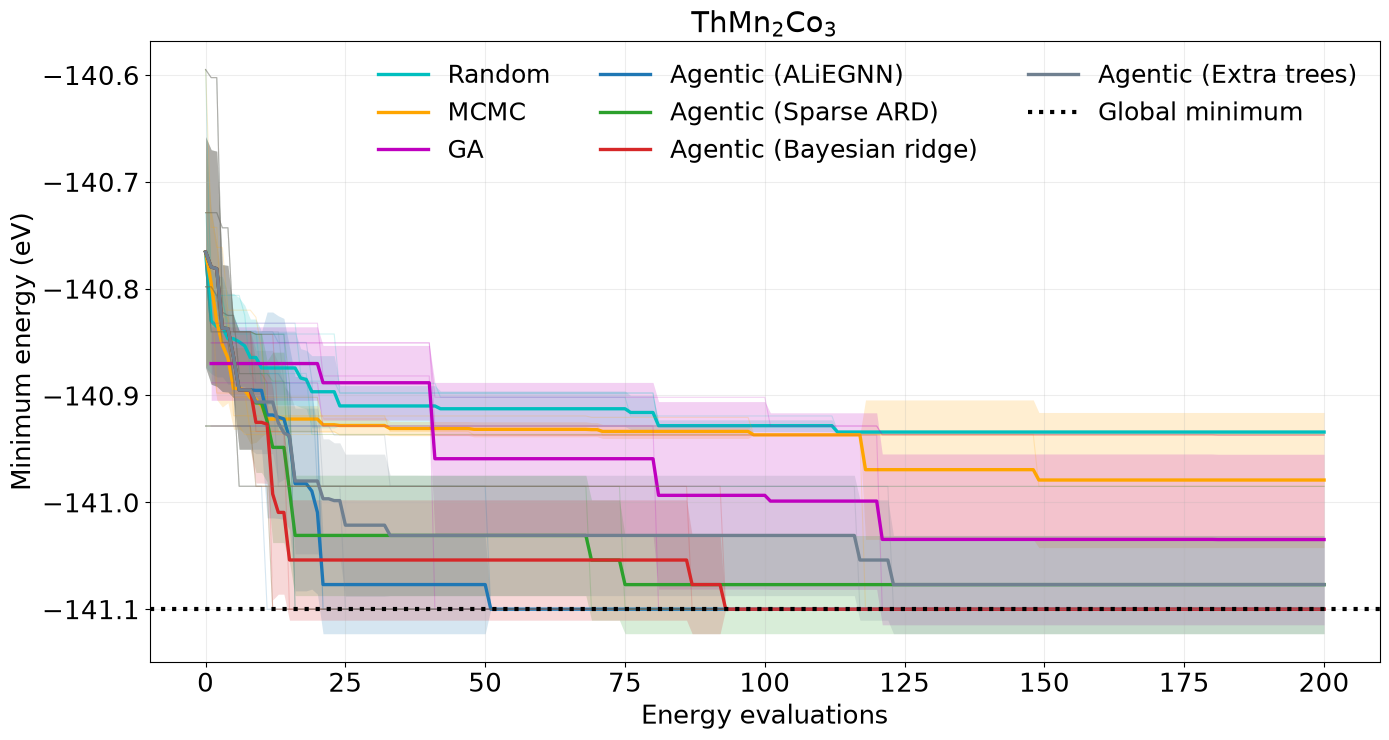

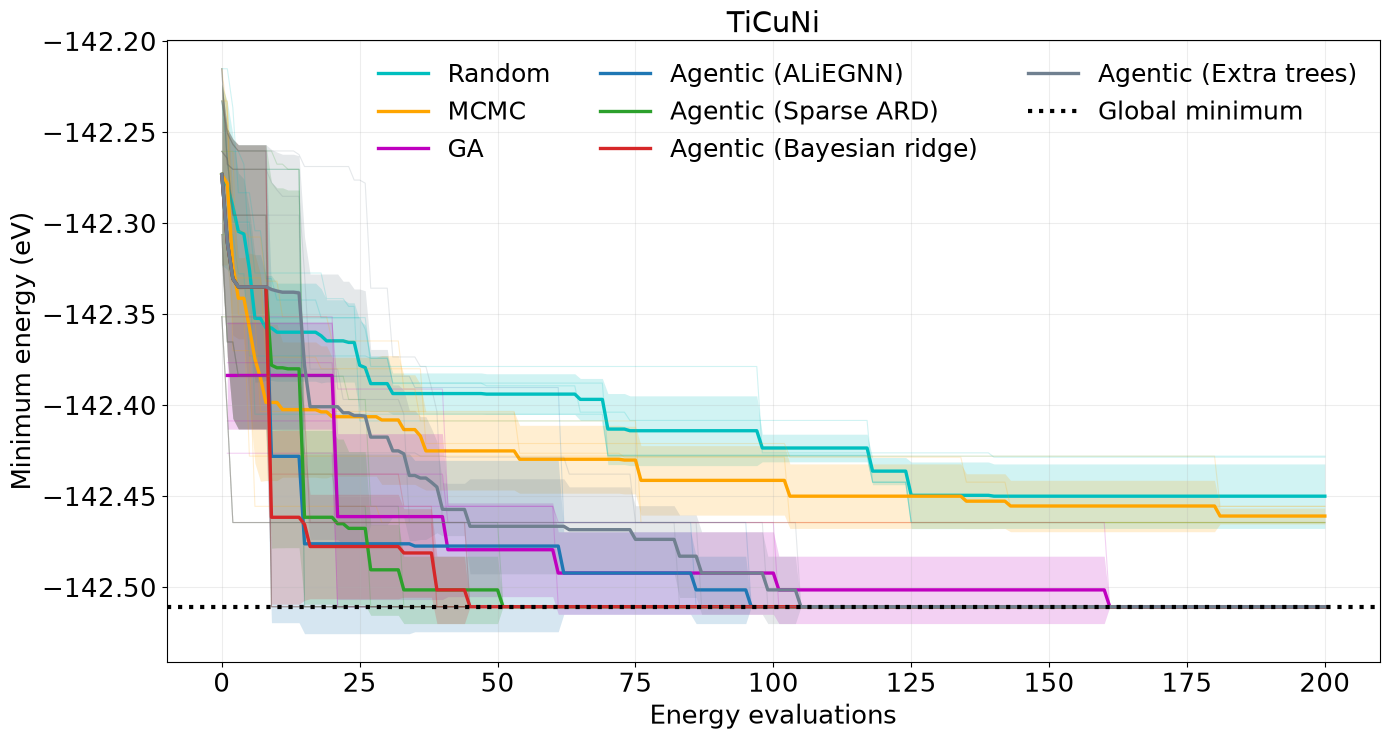

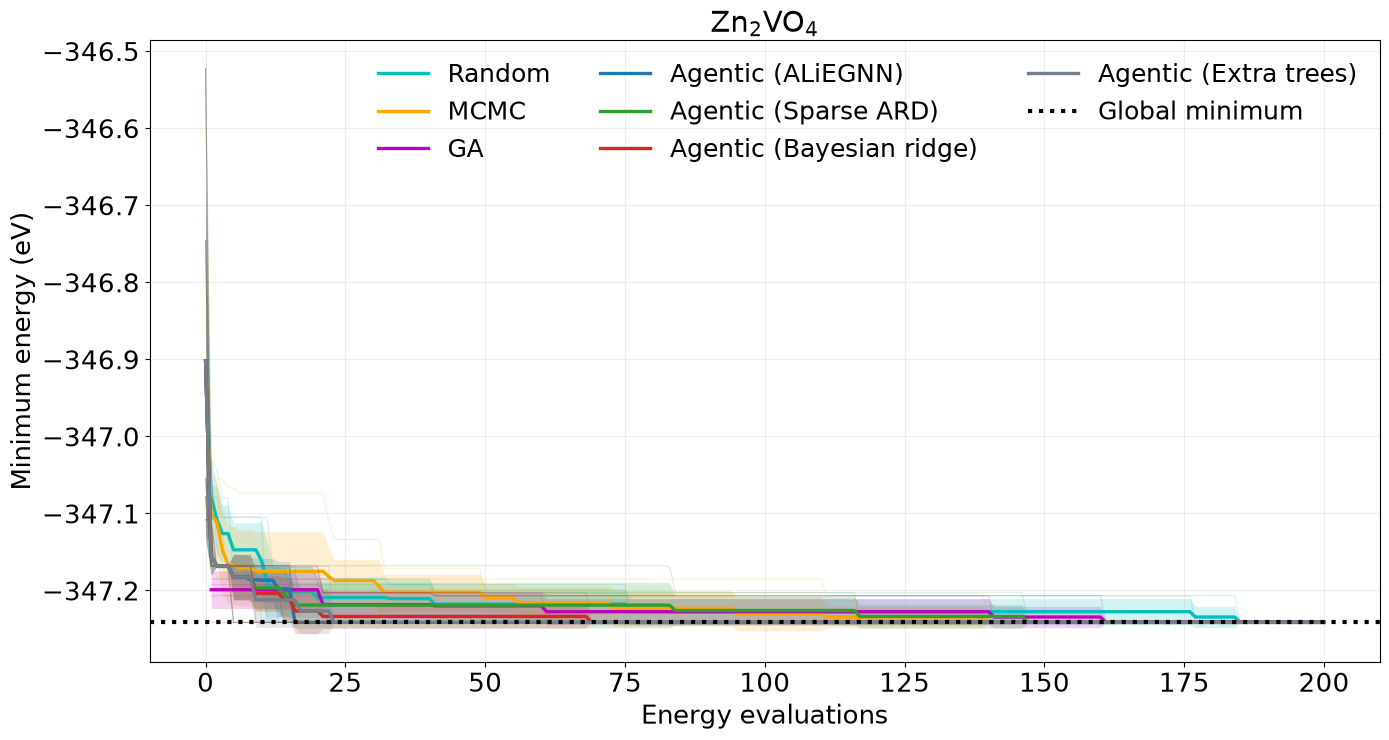

In [4]:
def plot_material(system, fontsize=16, title=True):
    g = groups(system)
    grid = np.arange(MAX_EVALUATIONS + 1)
    fig, ax = plt.subplots(figsize=(14, 7.5))
    for key, name, color in METHOD_SPECS:
        if key in g:
            draw_group(ax, g[key], color, name, grid)
    ref = reference(system)
    if ref is not None:
        ax.axhline(ref, color='black', ls=':', lw=3, label='Global minimum')
    ax.set_xlabel('Energy evaluations', fontsize=fontsize)
    ax.set_ylabel('Minimum energy (eV)', fontsize=fontsize)
    if title:
        ax.set_title(f'{SYSTEM_NAME.get(system, system)}', fontsize=fontsize+2)
    ax.grid(alpha=.22)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.legend(fontsize=fontsize - 1, ncol=3, frameon=False)
    fig.tight_layout()
    plt.show()

AGENTIC_PREFIX = 'agentic_without_unique_database_all15_four_surrogates_five_seeds_v1_'
# 16 in font for the example plot

METHOD_SPECS = [
    ('random', BASE_LABELS['random'], BASE_COLORS['random']),
    ('mc', BASE_LABELS['mc'], BASE_COLORS['mc']),
    ('ga', BASE_LABELS['ga'], BASE_COLORS['ga']),
    (AGENTIC_PREFIX + 'aliegnn_online', 'Agentic (ALiEGNN)', '#1f77b4'),
    (AGENTIC_PREFIX + 'ard', 'Agentic (Sparse ARD)', '#2ca02c'),
    (AGENTIC_PREFIX + 'bayesian_ridge', 'Agentic (Bayesian ridge)', '#d62728'),
    (AGENTIC_PREFIX + 'extra_trees', 'Agentic (Extra trees)', 'slategrey'),
    ('nafega_nNa16_bayesian_mace', 'Agentic (MACE Bayesian)', '#9467bd'),
]

SYSTEM_NAME = {
    'AlReGe': r'Al$_{1.25}$Ge$_{0.75}$Re',
    'Ba2ScTaO6': r'BaSc$_{0.5}$Ta$_{0.5}$O$_{3}$',
    'CoPt': 'CoPt',
    'Cu3Au': r'Au$_{0.8}$Cu$_{0.2}$ (1$\times$1$\times$5)',
    'Cu3Au_123': r'Au$_{0.8}$Cu$_{0.2}$ (1$\times$2$\times$3)',
    'FeCo': r'FeCo (2$\times$2$\times$2)',
    'FeCo_331': r'FeCo (3$\times$3$\times$1)',
    'FePt': r'Fe$_{3}$Pt',
    'InCuTe2': r'CuInTe$_{2}$',
    'LiYS2': r'LiYS$_{2}$',
    #'NaSbSe2': r'NaSbSe$_{2}$',
    'Ni2SbTe2': r'Ni$_{2}$SbTe',
    'ThMn2Co3': r'ThMn$_{2}$Co$_{3}$',
    'TiCuNi': 'TiCuNi',
    'V2ZnO4': r'Zn$_{2}$VO$_{4}$',
    'NaFeGaPO4_nNa16': r'Na$_{16}$Fe$_{16}$Ga$_{8}$(PO$_{4}$)$_{24}$',
}

plot_material('Cu3Au_123',fontsize=16,title=False)

for mat in SYSTEMS:
    plot_material(mat,fontsize=19,title=True)



/home/mahpe/Code/Agentic_optimizer/Agenticoptimizer_old/notebook_convergence_plots/steps_to_global_minimum_four_agentic_by_system.png


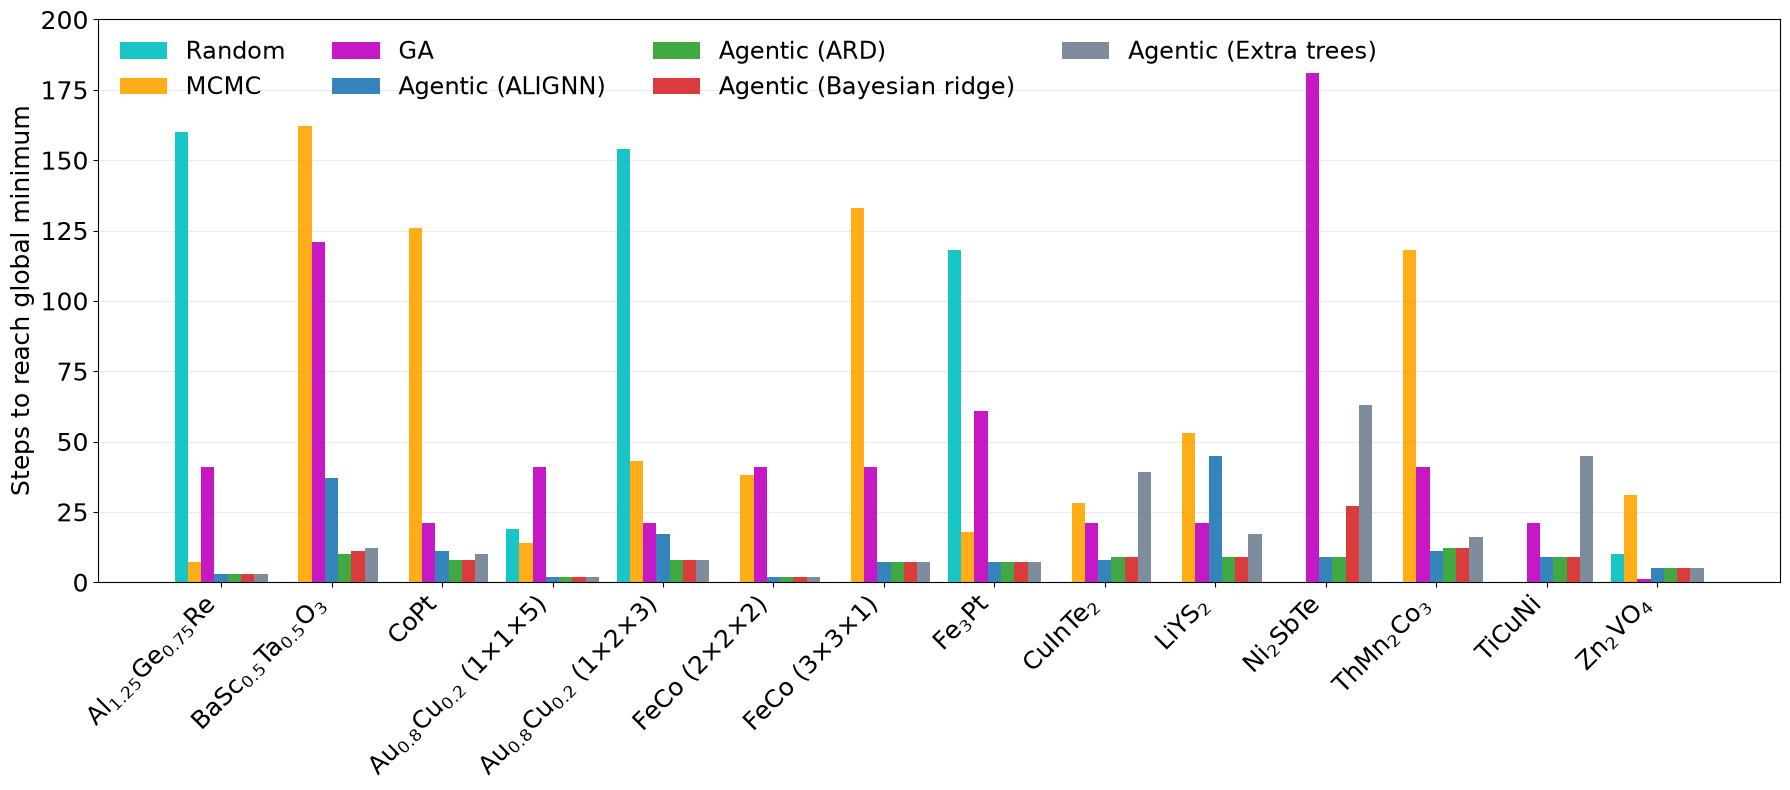

In [9]:
# Steps to reach the global minimum vs system (methods in the legend).
TOL_EV = 2e-5
AGENTIC_PREFIX = 'agentic_without_unique_database_all15_four_surrogates_five_seeds_v1_'
METHOD_SPECS = [
    ('random', BASE_LABELS['random'], BASE_COLORS['random']),
    ('mc', BASE_LABELS['mc'], BASE_COLORS['mc']),
    ('ga', BASE_LABELS['ga'], BASE_COLORS['ga']),
    (AGENTIC_PREFIX + 'aliegnn_online', 'Agentic (ALIGNN)', '#1f77b4'),
    (AGENTIC_PREFIX + 'ard', 'Agentic (ARD)', '#2ca02c'),
    (AGENTIC_PREFIX + 'bayesian_ridge', 'Agentic (Bayesian ridge)', '#d62728'),
    (AGENTIC_PREFIX + 'extra_trees', 'Agentic (Extra trees)', 'slategrey'),
    ('nafega_nNa16_bayesian_mace', 'Agentic (MACE Bayesian)', '#9467bd'),
]

def first_hit(x, y, target, tol=TOL_EV):
    hit = np.flatnonzero(np.asarray(y, float) <= float(target) + tol)
    return int(x[hit[0]]) if len(hit) else None

# Best (fewest) first-hit evaluation among seeds that reached the GM.
hit_steps = {key: [] for key, _, _ in METHOD_SPECS}
for system in SYSTEMS:
    ref = reference(system)
    g = groups(system)
    for key, _, _ in METHOD_SPECS:
        curves = g.get(key, [])
        if ref is None or not curves:
            hit_steps[key].append(np.nan)
            continue
        hits = [h for x, y in curves if (h := first_hit(x, y, ref)) is not None]
        hit_steps[key].append(float(min(hits)) if hits else np.nan)

fig, ax = plt.subplots(figsize=(18, 8))
fontsize=18
x = np.arange(len(SYSTEMS))
width = 0.12
for i, (key, name, color) in enumerate(METHOD_SPECS):
    vals = np.asarray(hit_steps[key], float)
    offset = (i - (len(METHOD_SPECS) - 1) / 2) * width
    ax.bar(x + offset, vals, width=width, label=name, color=color, alpha=0.9, zorder=3)

ax.set_xticks(x)
ax.set_xticklabels([SYSTEM_NAME.get(system, system) for system in SYSTEMS], rotation=45, ha='right')
ax.set_ylabel('Steps to reach global minimum',fontsize=fontsize)
#ax.set_xlabel('System',fontsize=fontsize)
ax.set_ylim(0, MAX_EVALUATIONS)
ax.tick_params(axis='both',labelsize=fontsize)
ax.legend(frameon=False, ncol=4,fontsize=fontsize-1)
ax.grid(axis='y', alpha=0.25, zorder=0)
fig.tight_layout()
out = OUTPUT_DIR / 'steps_to_global_minimum_four_agentic_by_system.png'
#fig.savefig(out, dpi=180, bbox_inches='tight')
print(out)
plt.show()



In [7]:
len(SYSTEMS)

14